In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Project root, assuming the notebook runs from notebooks/
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PATH = DATA_DIR / "application_train.csv"

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# Column names and data types
df.info()

# Number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Numerical summary
display(df.describe().T)

# Categorical summary
display(df.describe(include="object").T)

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 286.2 MB
Rows: 307511
Columns: 122


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


/var/folders/t3/m0ynk3_d65d934n81x8fz4740000gn/T/ipykernel_7679/1965842562.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232
CODE_GENDER,307511,3,F,202448
FLAG_OWN_CAR,307511,2,N,202924
FLAG_OWN_REALTY,307511,2,Y,213312
NAME_TYPE_SUITE,306219,7,Unaccompanied,248526
NAME_INCOME_TYPE,307511,8,Working,158774
NAME_EDUCATION_TYPE,307511,5,Secondary / secondary special,218391
NAME_FAMILY_STATUS,307511,6,Married,196432
NAME_HOUSING_TYPE,307511,6,House / apartment,272868
OCCUPATION_TYPE,211120,18,Laborers,55186


In [4]:
target_counts = df["TARGET"].value_counts().sort_index()
target_pct = df["TARGET"].value_counts(
    normalize=True
).sort_index() * 100

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_pct.round(2)
})

display(target_summary)

,count,percentage
TARGET,,
0,282686,91.93
1,24825,8.07


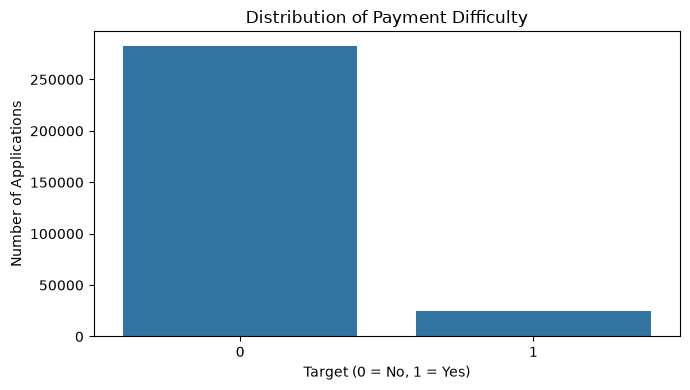

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.countplot(
    data=df,
    x="TARGET",
    order=[0, 1],
    ax=ax
)

ax.set_title("Distribution of Payment Difficulty")
ax.set_xlabel("Target (0 = No, 1 = Yes)")
ax.set_ylabel("Number of Applications")

plt.tight_layout()
plt.show()

In [6]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing = missing[
    missing["missing_count"] > 0
].sort_values("missing_pct", ascending=False)

display(missing.head(20).round(2))

,missing_count,missing_pct
COMMONAREA_MEDI,214865,69.87
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_MODE,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_AVG,210199,68.35


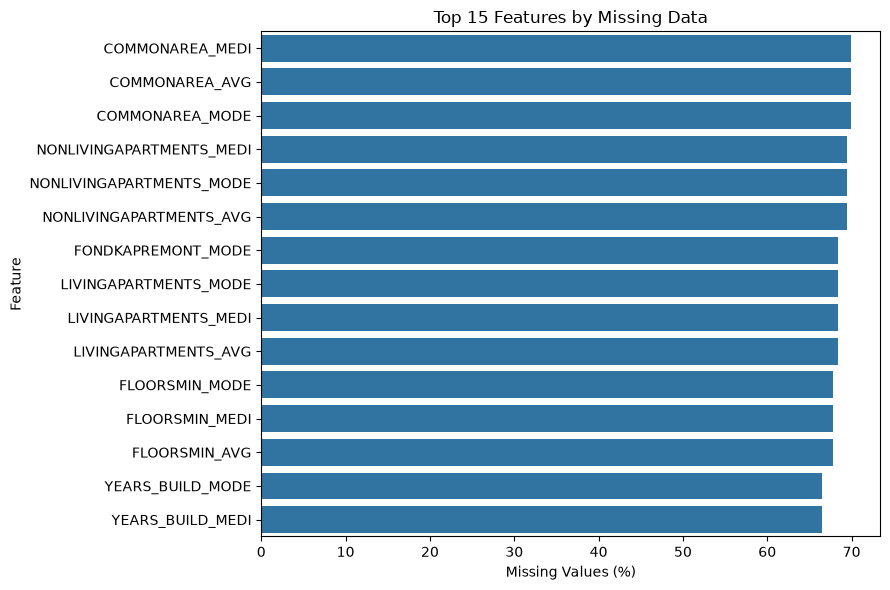

In [7]:
top_missing = missing.head(15)

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=top_missing.reset_index(),
    x="missing_pct",
    y="index",
    ax=ax
)

ax.set_title("Top 15 Features by Missing Data")
ax.set_xlabel("Missing Values (%)")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()


In [8]:
columns = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

display(
    df[columns].describe(
        percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
    ).T
)

# Check suspicious employment values
print(
    "Employment sentinel count:",
    (df["DAYS_EMPLOYED"] == 365243).sum()
)

# Check categorical values
display(df["CODE_GENDER"].value_counts(dropna=False))

,count,mean,std,min,1%,25%,50%,75%,99%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,45000.00,112500.0,147150.0,202500.0,472500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,76410.00,270000.0,513531.0,808650.0,1854000.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,6182.91,16524.0,24903.0,34596.0,70006.5,258025.5
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.0,-24419.00,-19682.0,-15750.0,-12413.0,-8263.0,-7489.0
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.0,-10894.90,-2760.0,-1213.0,-289.0,365243.0,365243.0


Employment sentinel count: 55374


CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

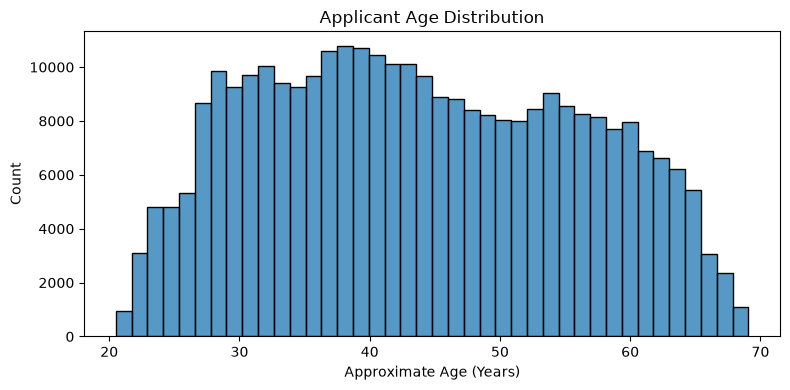

In [9]:
df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25

fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=df,
    x="AGE_YEARS",
    bins=40,
    ax=ax
)

ax.set_title("Applicant Age Distribution")
ax.set_xlabel("Approximate Age (Years)")

plt.tight_layout()
plt.show()

**SQL** with DuckDB

In [11]:
import duckdb

con = duckdb.connect()

# Convert the file path to a string
csv_path = DATA_PATH.as_posix()

# Create a view of the dataset
con.execute(f"""
    CREATE OR REPLACE VIEW applications AS
    SELECT *
    FROM read_csv_auto('{csv_path}')
""")

# Preview the data
con.sql("SELECT * FROM applications LIMIT 5").df()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
query = """
SELECT
    TARGET,
    COUNT(*) AS application_count,
    ROUND(
        100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER (),
        2
    ) AS percentage
FROM applications
GROUP BY TARGET
ORDER BY TARGET
"""

display(con.sql(query).df())

,TARGET,application_count,percentage
0,0,282686,91.93
1,1,24825,8.07


In [13]:
query = """
SELECT
    NAME_INCOME_TYPE,
    COUNT(*) AS total_applicants,
    SUM(TARGET) AS difficulty_cases,
    ROUND(
        100.0 * AVG(TARGET),
        2
    ) AS difficulty_rate_pct
FROM applications
GROUP BY NAME_INCOME_TYPE
ORDER BY difficulty_rate_pct DESC;
"""
display(con.sql(query).df())

,NAME_INCOME_TYPE,total_applicants,difficulty_cases,difficulty_rate_pct
0,Maternity leave,5,2.0,40.00
1,Unemployed,22,8.0,36.36
2,Working,158774,15224.0,9.59
3,Commercial associate,71617,5360.0,7.48
4,State servant,21703,1249.0,5.75
5,Pensioner,55362,2982.0,5.39
6,Businessman,10,0.0,0.00
7,Student,18,0.0,0.00


In [16]:
query = """ 
WITH loan_ratios AS (
    SELECT
        SK_ID_CURR,
        TARGET,
        AMT_CREDIT / NULLIF(AMT_INCOME_TOTAL, 0)
            AS credit_to_income_ratio
    FROM applications
    WHERE AMT_INCOME_TOTAL > 0
),
risk_groups AS (
    SELECT
        TARGET,
        CASE
            WHEN credit_to_income_ratio < 1 THEN 'Under 1'
            WHEN credit_to_income_ratio < 2 THEN '1 to 2'
            WHEN credit_to_income_ratio < 3 THEN '2 to 3'
            WHEN credit_to_income_ratio < 5 THEN '3 to 5'
            ELSE '5 or more'
        END AS ratio_group
    FROM loan_ratios
)
SELECT
    ratio_group,
    COUNT(*) AS applicants,
    ROUND(
        100.0 * AVG(TARGET),
        2
    ) AS difficulty_rate_pct
FROM risk_groups
GROUP BY ratio_group
ORDER BY 
    CASE ratio_group
        WHEN 'Under 1' THEN 1
        WHEN '1 to 2' THEN 2
        WHEN '2 to 3' THEN 3
        WHEN '3 to 5' THEN 4
        ELSE 5
    END;
"""
display(con.sql(query).df())

,ratio_group,applicants,difficulty_rate_pct
0,Under 1,14238,6.55
1,1 to 2,56798,7.72
2,2 to 3,66240,8.70
3,3 to 5,86309,8.75
4,5 or more,83926,7.38


In [18]:
query = """
WITH applicant_ages AS (
    SELECT
        TARGET,
        FLOOR(-DAYS_BIRTH / 365.25) AS age
    FROM applications
)
SELECT
    CASE
        WHEN age < 30 THEN 'Under 30'
        WHEN age < 40 THEN '30-39'
        WHEN age < 50 THEN '40-49'
        WHEN age < 60 THEN '50-59'
        ELSE '60+'
    END AS age_group,
    COUNT(*) AS applicants,
    ROUND(
        100.0 * AVG(TARGET),
        2
    ) AS difficulty_rate_pct
FROM applicant_ages
GROUP BY age_group
ORDER BY 
    CASE age_group
        WHEN 'Under 30' THEN 1
        WHEN '30-39' THEN 2
        WHEN '40-49' THEN 3
        WHEN '50-59' THEN 4
        ELSE 5
    END;
"""
display(con.sql(query).df())

,age_group,applicants,difficulty_rate_pct
0,Under 30,45186,11.44
1,30-39,82331,9.59
2,40-49,76599,7.64
3,50-59,68094,6.12
4,60+,35301,4.92
